# Marketing Attribution: Rule-Based vs. Data-Driven (Markov) Models

**Question.** Last-touch reporting credits whoever is present at the moment of purchase. Which channels does that mislead us about,
and how should budget decisions change under a data-driven model?

**Data.** 100,000 customer journeys (7.0% convert), 295K touches across 7 channels, one quarter of spend. Rule-based models are computed in SQL
(`sql/attribution_queries.sql`); the Markov model is built here.

> Journeys are simulated from a known Markov process (`src/generate_data.py`), which lets us do something real data never allows:
> **check the estimated channel contributions against the true ones** (section 5).

In [1]:
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
ROOT = Path("..").resolve(); PROC, ASSETS, RESULTS = ROOT/"data/processed", ROOT/"assets", ROOT/"results"
ASSETS.mkdir(exist_ok=True); RESULTS.mkdir(exist_ok=True)
sys.path.insert(0, str(ROOT/"src"))
from generate_data import true_transition_matrix, CHANNELS

BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8985"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .25, "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10})
M = {}
paths = pd.read_csv(PROC/"attr_paths.csv")
rule = pd.read_csv(PROC/"attr_rule_based.csv").set_index("channel")
assist = pd.read_csv(PROC/"attr_assist_ratio.csv").set_index("channel")
spend = pd.read_csv(ROOT/"data/raw/channel_spend.csv").set_index("channel").spend
paths["seq"] = paths.path.str.split(" > ")
total_conv, total_rev = int(paths.converted.sum()), float(paths.loc[paths.converted == 1, "revenue"].sum())
print(f"journeys={len(paths):,}  conversions={total_conv:,} ({paths.converted.mean():.1%})  revenue=${total_rev:,.0f}")
M.update(journeys=len(paths), conversions=total_conv, conversion_rate_pct=round(100*paths.converted.mean(), 2), revenue=round(total_rev))

journeys=100,000  conversions=6,992 (7.0%)  revenue=$556,957


## 1. What do converting journeys look like?

In [2]:
conv = paths[paths.converted == 1]
print("Touches per converted journey:", conv.seq.str.len().describe()[["mean", "50%", "max"]].round(2).to_dict())
top = conv.path.value_counts().head(8).rename("conversions").to_frame(); top["share_pct"] = (100*top.conversions/total_conv).round(1)
display(top)
single = (conv.seq.str.len() == 1).mean()
print(f"{single:.0%} of conversions are single-touch; {1-single:.0%} involve multiple channels, where attribution choices matter.")
print("\nAssists vs. closes (SQL):"); display(assist)
M["multi_touch_share_pct"] = round(100*(1-single), 1)
M["top_paths"] = top.reset_index().rename(columns={"path": "path"}).to_dict(orient="records")

Touches per converted journey: {'mean': 3.2, '50%': 3.0, 'max': 10.0}


,conversions,share_pct
path,,
direct,443,6.3
organic_search,390,5.6
paid_search,384,5.5
email,188,2.7
paid_social,171,2.4
organic_search > direct,161,2.3
paid_search > direct,119,1.7
organic_search > email,116,1.7


25% of conversions are single-touch; 75% involve multiple channels, where attribution choices matter.

Assists vs. closes (SQL):


,assists,closes,assist_to_close_ratio
channel,,,
display,1262.0,87.0,14.51
paid_social,1479.0,267.0,5.54
affiliate,1225.0,315.0,3.89
organic_search,3108.0,978.0,3.18
paid_search,2649.0,1143.0,2.32
email,2160.0,1563.0,1.38
direct,3494.0,2639.0,1.32


## 2. Rule-based models (SQL), verified in Python

First touch, last touch, linear, position-based (40/20/40) and time-decay (7-day half-life) are computed with window functions.
We re-derive three of them independently in pandas as a correctness check.

In [3]:
first = conv.seq.str[0].value_counts(); last = conv.seq.str[-1].value_counts()
lin = pd.Series(0.0, index=CHANNELS)
for s in conv.seq:
    for ch in s: lin[ch] += 1/len(s)
check = pd.DataFrame({"first": first, "last": last, "linear": lin}).reindex(CHANNELS).fillna(0)
ok = (np.allclose(check["first"], rule.loc[CHANNELS, "first_touch_conv"], atol=.1) and np.allclose(check["last"], rule.loc[CHANNELS, "last_touch_conv"], atol=.1)
      and np.allclose(check["linear"], rule.loc[CHANNELS, "linear_conv"], atol=.2))
print("Python re-derivation matches SQL for first / last / linear:", ok)
assert ok

models = rule[[c for c in rule.columns if c.endswith("_conv")]].copy()
models.columns = ["First touch", "Last touch", "Linear", "Position-based", "Time decay"]
display((100*models/models.sum()).round(1).assign(**{"Assist:close": assist.assist_to_close_ratio}))

Python re-derivation matches SQL for first / last / linear: True


,First touch,Last touch,Linear,Position-based,Time decay,Assist:close
channel,,,,,,
affiliate,7.0,4.5,6.3,6.0,6.2,3.89
direct,15.6,37.7,27.0,26.7,28.2,1.32
display,12.6,1.2,5.9,6.5,5.3,14.51
email,7.0,22.4,15.2,14.9,16.0,1.38
organic_search,24.0,14.0,19.2,19.1,18.7,3.18
paid_search,18.3,16.3,18.0,17.6,17.9,2.32
paid_social,15.5,3.8,8.5,9.2,7.8,5.54


## 3. Data-driven attribution: first-order Markov chain with removal effect

1. Estimate transition probabilities between channels from *all* journeys (converting and non-converting), with absorbing states `CONVERSION` and `NULL`.
2. For each channel, delete it from the graph (all inbound traffic falls to `NULL`) and recompute the overall conversion probability.
3. The **removal effect** is the relative drop in conversion probability; credit is allocated in proportion to removal effects.

This rewards channels that the journey actually *depends on*, including assists that never appear last.

In [4]:
STATES = ["START"] + CHANNELS + ["CONVERSION", "NULL"]
def estimate_T(df):
    cnt = pd.DataFrame(0.0, index=STATES, columns=STATES)
    for seq, c in zip(df.seq, df.converted):
        full = ["START"] + seq + ["CONVERSION" if c else "NULL"]
        for a, b in zip(full[:-1], full[1:]): cnt.loc[a, b] += 1
    cnt.loc["CONVERSION", "CONVERSION"] = 1; cnt.loc["NULL", "NULL"] = 1
    return cnt.div(cnt.sum(axis=1), axis=0).fillna(0)

def conv_prob(T):
    tr = ["START"] + CHANNELS
    Q, R = T.loc[tr, tr].values, T.loc[tr, ["CONVERSION"]].values
    return float((np.linalg.inv(np.eye(len(tr)) - Q) @ R)[0, 0])

def removal_effects(T):
    base = conv_prob(T); out = {}
    for k in CHANNELS:
        T2 = T.copy(); T2["NULL"] += T2[k]; T2[k] = 0.0       # inbound traffic to k is lost
        out[k] = 1 - conv_prob(T2) / base
    return pd.Series(out), base

T_hat = estimate_T(paths)
re_hat, p_hat = removal_effects(T_hat)
print(f"Model conversion probability from START: {p_hat:.3%}  (observed {paths.converted.mean():.3%})")
markov_conv = re_hat / re_hat.sum() * total_conv
display(pd.DataFrame({"removal_effect_pct": (100*re_hat).round(1), "credited_conversions": markov_conv.round(0)}).sort_values("removal_effect_pct", ascending=False))

Model conversion probability from START: 6.992%  (observed 6.992%)


,removal_effect_pct,credited_conversions
direct,56.8,1631.0
organic_search,44.7,1285.0
email,41.8,1199.0
paid_search,41.2,1184.0
paid_social,21.8,627.0
affiliate,19.4,557.0
display,17.7,509.0


## 4. How much do the models disagree?

,First touch,Last touch,Linear,Markov
channel,,,,
direct,15.6,37.7,27.0,23.3
organic_search,24.0,14.0,19.2,18.4
email,7.0,22.4,15.2,17.2
paid_search,18.3,16.3,18.0,16.9
paid_social,15.5,3.8,8.5,9.0
affiliate,7.0,4.5,6.3,8.0
display,12.6,1.2,5.9,7.3


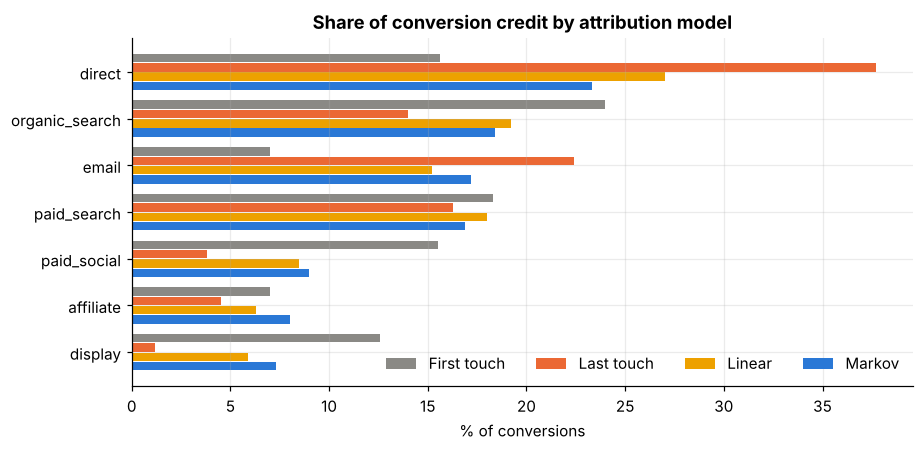

Markov credit relative to last-touch credit (%):


channel
direct            -38.0
email             -23.0
paid_search         4.0
organic_search     31.0
affiliate          77.0
paid_social       135.0
display           485.0
Name: markov_vs_last_touch_pct, dtype: float64

In [5]:
share = (models / models.sum()); share["Markov"] = markov_conv / markov_conv.sum()
order = share.sort_values("Markov", ascending=False).index
cmp = (100*share.loc[order, ["First touch", "Last touch", "Linear", "Markov"]]).round(1)
display(cmp)

fig, ax = plt.subplots(figsize=(8.5, 4.2)); h = .2; y = np.arange(len(order))[::-1]
for i, (col, color) in enumerate(zip(["First touch", "Last touch", "Linear", "Markov"], [GREY, ORANGE, YELLOW, BLUE])):
    ax.barh(y + (1.5 - i)*h, cmp[col], h*.9, color=color, label=col)
ax.set_yticks(y); ax.set_yticklabels(order); ax.set(title="Share of conversion credit by attribution model", xlabel="% of conversions"); ax.legend(frameon=False, ncol=4, loc="lower right")
plt.tight_layout(); plt.savefig(ASSETS/"06_credit_by_model.png", dpi=150, bbox_inches="tight"); plt.show()

gap = (100*(share["Markov"]/share["Last touch"] - 1)).round(0).rename("markov_vs_last_touch_pct")
print("Markov credit relative to last-touch credit (%):"); display(gap.sort_values())
M["credit_share_pct"] = cmp.to_dict(orient="index"); M["markov_vs_last_touch_pct"] = gap.to_dict()
M["removal_effect_pct"] = (100*re_hat).round(1).to_dict()

## 5. Validation against ground truth

Because we generated the journeys, we can compute the *true* removal effects from the generating matrix and see how well the estimated chain recovers them.

,true_%,estimated_%,abs_error_pts
direct,23.02,23.32,0.30
organic_search,18.39,18.38,0.01
email,17.37,17.15,0.22
paid_search,17.07,16.93,0.14
paid_social,8.88,8.97,0.09
affiliate,7.99,7.97,0.02
display,7.27,7.28,0.01


correlation = 0.9996; max absolute error = 0.30 pts of credit share


,misallocated_credit_%
Markov,0.4
Position-based,5.3
Linear,5.7
Time decay,6.3
First touch,18.8
Last touch,19.7


(share of total credit assigned to the wrong channel, relative to the true contribution)


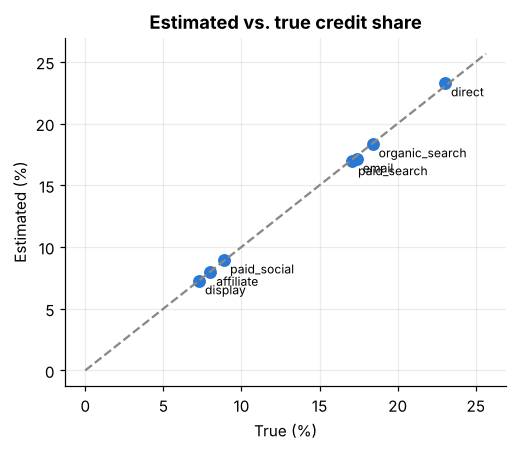

In [6]:
T_true = true_transition_matrix()
re_true, p_true = removal_effects(T_true)
cmp_true = pd.DataFrame({"true_%": 100*re_true/re_true.sum(), "estimated_%": 100*re_hat/re_hat.sum()}).round(2)
cmp_true["abs_error_pts"] = (cmp_true["estimated_%"] - cmp_true["true_%"]).abs().round(2)
display(cmp_true.sort_values("true_%", ascending=False))
corr = np.corrcoef(cmp_true["true_%"], cmp_true["estimated_%"])[0, 1]
print(f"correlation = {corr:.4f}; max absolute error = {cmp_true.abs_error_pts.max():.2f} pts of credit share")

# how wrong are the rule-based models vs. the truth?
true_share = re_true / re_true.sum()
err = pd.DataFrame({m: (share.loc[CHANNELS, m] - true_share).abs().sum() / 2 * 100 for m in ["First touch", "Last touch", "Linear", "Position-based", "Time decay", "Markov"]}, index=["misallocated_credit_%"]).T.round(1)
display(err.sort_values("misallocated_credit_%"))
print("(share of total credit assigned to the wrong channel, relative to the true contribution)")
M["validation"] = dict(corr=round(float(corr), 4), max_abs_error_pts=float(cmp_true.abs_error_pts.max()), misallocated_pct=err["misallocated_credit_%"].to_dict())
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.scatter(cmp_true["true_%"], cmp_true["estimated_%"], color=BLUE, s=55); lim = [0, cmp_true.max().max() * 1.1]
ax.plot(lim, lim, color=GREY, ls="--"); ax.set(title="Estimated vs. true credit share", xlabel="True (%)", ylabel="Estimated (%)")
for ch, r in cmp_true.iterrows(): ax.annotate(ch, (r["true_%"], r["estimated_%"]), fontsize=8, xytext=(4, -9), textcoords="offset points")
plt.tight_layout(); plt.savefig(ASSETS/"07_markov_vs_truth.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. From credit to budget: CPA and ROAS under each model

Direct traffic carries no media spend, so it is excluded from efficiency metrics (its credit is still counted in shares).
Revenue per conversion is independent of channel in this data, so revenue credit follows conversion credit.

ROAS                  CPA ($)                spend
               Last touch Linear Markov Last touch Linear Markov       
email               15.46  10.43  11.94        5.0    8.0    7.0   8000
organic_search       3.10   4.32   4.09       26.0   19.0   19.0  25000
affiliate            2.05   2.80   3.70       38.0   27.0   22.0  12000
paid_search          2.86   3.15   2.95       28.0   25.0   27.0  32000
display              0.31   1.49   1.84      253.0   54.0   43.0  22000
paid_social          0.71   1.57   1.67      112.0   51.0   48.0  30000

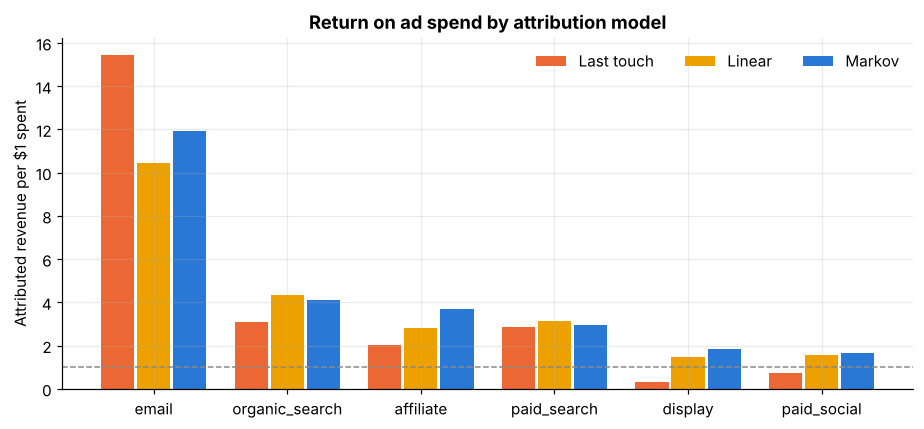

ROAS rank, last-touch -> Markov: {'paid_search': '3 -> 4', 'paid_social': '5 -> 6', 'email': '1 -> 1', 'organic_search': '2 -> 2', 'display': '6 -> 5', 'affiliate': '4 -> 3'}


In [7]:
paid = [c for c in CHANNELS if spend[c] > 0]
avg_rev = total_rev / total_conv
rev_credit = pd.DataFrame({"Last touch": rule.loc[paid, "last_touch_rev"], "Linear": rule.loc[paid, "linear_rev"], "Markov": markov_conv[paid] * avg_rev})
roas = rev_credit.div(spend[paid], axis=0).round(2)
cpa = (spend[paid].values[:, None] / pd.DataFrame({"Last touch": models.loc[paid, "Last touch"], "Linear": models.loc[paid, "Linear"], "Markov": markov_conv[paid]}).values).round(0)
cpa = pd.DataFrame(cpa, index=paid, columns=roas.columns)
eff = pd.concat({"ROAS": roas, "CPA ($)": cpa}, axis=1).assign(spend=spend[paid]).sort_values(("ROAS", "Markov"), ascending=False)
display(eff)

fig, ax = plt.subplots(figsize=(8.5, 4)); r = roas.loc[eff.index]; x = np.arange(len(r)); w = .27
for i, (col, color) in enumerate(zip(["Last touch", "Linear", "Markov"], [ORANGE, YELLOW, BLUE])): ax.bar(x + (i-1)*w, r[col], w*.92, color=color, label=col)
ax.axhline(1, color=GREY, ls="--", lw=1); ax.set_xticks(x); ax.set_xticklabels(r.index); ax.set(title="Return on ad spend by attribution model", ylabel="Attributed revenue per $1 spent"); ax.legend(frameon=False, ncol=3)
plt.tight_layout(); plt.savefig(ASSETS/"08_roas_by_model.png", dpi=150, bbox_inches="tight"); plt.show()
M["roas"] = {k: roas[k].round(2).to_dict() for k in roas.columns}; M["cpa"] = {k: cpa[k].to_dict() for k in cpa.columns}
M["spend"] = spend.to_dict()
rank_ls = roas["Last touch"].rank(ascending=False).astype(int); rank_mk = roas["Markov"].rank(ascending=False).astype(int)
M["rank_change"] = {c: [int(rank_ls[c]), int(rank_mk[c])] for c in paid}
print("ROAS rank, last-touch -> Markov:", {c: f"{rank_ls[c]} -> {rank_mk[c]}" for c in paid})

## 7. Takeaways

* **Last-touch rewards closers and punishes openers.** Direct and email look strongest under last-touch; display and paid social are almost invisible as closers yet they
  start a large share of converting journeys and carry real removal effects.
* **The Markov model recovers the true contributions closely** (section 5), while single-touch rules misallocate a large fraction of credit. This validation is favourable by construction, because the journeys come from a first-order Markov process; on real data expect a looser fit.
  Linear and position-based models are reasonable middle grounds when journey data is thin.
* **Budget implication.** Efficiency rankings change by model. Cutting display or paid social because last-touch ROAS looks poor would remove traffic that feeds later conversions.
  Conversely, spend should not be *increased* on the strength of attribution alone.
* **Attribution is not incrementality.** All of these models are descriptive allocations of observed conversions. Before moving large budgets, validate the biggest disagreements
  with a geo or holdout experiment, analysed with the methods in `01_ab_test_analysis.ipynb`.
* **Limits.** A first-order chain ignores long-range order effects; the real world adds untracked touches (offline, cross-device) and selection effects (people who already intend to buy
  click branded search and email).

In [8]:
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    return o
(RESULTS/"attribution_metrics.json").write_text(json.dumps(clean(M), indent=2)); print("saved results/attribution_metrics.json")

saved results/attribution_metrics.json
